In [2]:
%load_ext autoreload
%autoreload 2

import sys
sys.path.append("..")

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

from src.simulation import simulate_gbm
from src.black_scholes import bs_price, bs_delta
from src.hedging import compute_pnl, bs_delta_strategy

In [3]:
S0, K, sigma, T, n_steps = 100, 100, 0.2, 30/365, 30
dt = T / n_steps

S = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=42)
S_t = torch.tensor(S, dtype=torch.float32)

p0 = bs_price(S0, K, T, sigma)

In [4]:
tau = T - np.arange(n_steps) * dt

x1 = torch.log(S_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2 = torch.tensor(tau / T, dtype=torch.float32).expand(S_t.shape[0], n_steps)
features = torch.stack([x1, x2], dim=-1)

print(features.shape, features[0, 0])

torch.Size([100000, 30, 2]) tensor([0., 1.])


In [5]:
net_tc = nn.Sequential(
    nn.Linear(3, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)

In [6]:
idx = torch.randint(0, S_t.shape[0], (10_000,))
S_b  = S_t[idx]
x1_b = x1[idx]
x2_b = x2[idx]



B = x1_b.shape[0]                    
delta_prev = torch.zeros(B)          
k = 0
inp = torch.stack([x1_b[:, k], x2_b[:, k], delta_prev], dim=-1)   
delta_k = net_tc(inp).squeeze(-1)  

In [7]:
delta_prev = torch.zeros(B)
deltas_list = []

for k in range(n_steps):
    inp =torch.stack([x1_b[:, k], x2_b[:, k], delta_prev], dim=-1)       
    delta_k =  net_tc(inp).squeeze(-1)
    deltas_list.append(delta_k)
    delta_prev = delta_k
deltas = torch.stack(deltas_list, dim=1)
print(deltas.shape)

torch.Size([10000, 30])


In [8]:



def rollout(net, x1_b, x2_b):
    B = x1_b.shape[0]
    delta_prev = torch.zeros(B)
    deltas_list = []
    for k in range(n_steps):
        inp =torch.stack([x1_b[:, k], x2_b[:, k], delta_prev], dim=-1)        # тройка признаков дня k (строка у тебя уже есть
        delta_k =  net(inp).squeeze(-1)
        deltas_list.append(delta_k)
        delta_prev = delta_k
    deltas = torch.stack(deltas_list, dim=1)
    return deltas

deltas.shape

torch.Size([10000, 30])

In [9]:
def pnl_torch(S_b, deltas, p0, K, c):
    payoff = torch.clamp(S_b[:, -1] - K, min=0)
    hedge_gain = (deltas * (S_b[:, 1:] - S_b[:, :-1])).sum(dim=1)

    zeros = torch.zeros(deltas.shape[0], 1)
    prev = torch.cat([zeros, deltas[:, :-1]], dim=1)
    costs = (c * S_b[:, :-1] * torch.abs(deltas - prev)).sum(dim=1)

    return p0 - payoff + hedge_gain - costs

In [10]:
with torch.no_grad():
    d = rollout(net_tc, x1_b, x2_b)
    p_t = pnl_torch(S_b, d, p0, K, c=0.01)

p_np = compute_pnl(S_b.numpy(), d.numpy(), p0, K, c=0.01)
print(p_t[:5])
print(p_np[:5])

tensor([-4.1899, -9.3366,  0.0973,  2.3978,  1.8121])
[-4.18994279 -9.33659514  0.09730881  2.39776909  1.81214625]


In [11]:
net_tc = nn.Sequential(
    nn.Linear(3, 32), nn.ReLU(),
    nn.Linear(32, 32), nn.ReLU(),
    nn.Linear(32, 1),
)
w = torch.tensor(0.0, requires_grad=True)
alpha = 0.95
c = 0.01

optimizer = torch.optim.Adam([
    {"params": list(net_tc.parameters()), "lr": 1e-3},
    {"params": [w], "lr": 0.01},
])

In [12]:
import os
path = "../models/net_tc_c001.pt"

if os.path.exists(path):
    net_tc.load_state_dict(torch.load(path))
    print("loaded trained network from", path)
else:
    for i in range(3000):
        idx = torch.randint(0, S_t.shape[0], (10_000,))
        S_b, x1_b, x2_b = S_t[idx], x1[idx], x2[idx]
        deltas = rollout(net_tc, x1_b, x2_b)
        pnl = pnl_torch(S_b, deltas, p0, K, c)
        loss = w + torch.clamp(-pnl - w, min=0).mean() / (1 - alpha)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()
        if i % 300 == 0:
            print(i, loss.item(), w.item())
    torch.save(net_tc.state_dict(), path)

loaded trained network from ../models/net_tc_c001.pt


In [13]:
torch.save(net_tc.state_dict(), "../models/net_tc_c001.pt")

In [14]:
def cvar(pnl, alpha=0.95):
    losses = -pnl
    var = np.quantile(losses, alpha)
    return losses[losses >=var].mean()  

In [15]:
def report(name, pnl, deltas):
    prev = np.concatenate([np.zeros((deltas.shape[0], 1)), deltas[:, :-1]], axis=1)
    turnover = np.abs(deltas - prev).sum(axis=1).mean()
    print(f"{name:12s} mean={pnl.mean():.3f}  std={pnl.std():.3f}  CVaR95={cvar(pnl):.3f}  turnover={turnover:.2f}")

In [16]:
S_test = simulate_gbm(S0=S0, mu=0, sigma=sigma, T=T, n_steps=n_steps, n_paths=100_000, seed=1)
S_test_t = torch.tensor(S_test, dtype=torch.float32)
x1_test = torch.log(S_test_t[:, :-1] / K) / (sigma * np.sqrt(T))
x2_test = torch.tensor(tau / T, dtype=torch.float32).expand(S_test_t.shape[0], n_steps)

In [17]:
with torch.no_grad():
    d_net = rollout(net_tc, x1_test, x2_test).numpy()
d_bs   = bs_delta_strategy(S_test, K, T, sigma)
d_none = np.zeros_like(d_bs)

for name, d in [("No hedge", d_none), ("BS delta", d_bs), ("Network", d_net)]:
    pnl = compute_pnl(S_test, d, p0, K, c=c)
    report(name, pnl, d)

No hedge     mean=-0.016  std=3.466  CVaR95=10.064  turnover=0.00
BS delta     mean=-2.220  std=0.754  CVaR95=4.057  turnover=2.22
Network      mean=-1.241  std=0.638  CVaR95=2.410  turnover=1.24


In [18]:
from src.hedging import band_strategy

hs = np.arange(0.0, 0.31, 0.01)
cvars = []
for h in hs:
    d = band_strategy(S, K, T, sigma, h)
    cvars.append(cvar(compute_pnl(S, d, p0, K, c=c)))

h_best = hs[np.argmin(cvars)]
print(f"best h = {h_best:.2f}, train CVaR95 = {min(cvars):.3f}")

d_bs   = bs_delta_strategy(S_test, K, T, sigma)
d_band = band_strategy(S_test, K, T, sigma, h_best)

for name, d in [("BS delta", d_bs), (f"Band h={h_best:.2f}", d_band), ("Network", d_net)]:
    report(name, compute_pnl(S_test, d, p0, K, c=c), d)

best h = 0.11, train CVaR95 = 2.619
BS delta     mean=-2.220  std=0.754  CVaR95=4.057  turnover=2.22
Band h=0.11  mean=-1.036  std=0.713  CVaR95=2.609  turnover=1.03
Network      mean=-1.241  std=0.638  CVaR95=2.410  turnover=1.24


In [19]:
def train_tc_net(seed, n_iter=2000):
    torch.manual_seed(seed)

    net = nn.Sequential(
        nn.Linear(3, 32), nn.ReLU(),
        nn.Linear(32, 32), nn.ReLU(),
        nn.Linear(32, 1),
    )
    w = torch.tensor(0.0, requires_grad=True)
    opt = torch.optim.Adam([
        {"params": list(net.parameters()), "lr": 1e-3},
        {"params": [w], "lr": 0.01},
    ])

    for i in range(n_iter):
        idx = torch.randint(0, S_t.shape[0], (10_000,))
        S_b, x1_b, x2_b = S_t[idx], x1[idx], x2[idx]
        deltas = rollout(net, x1_b, x2_b)
        pnl = pnl_torch(S_b, deltas, p0, K, c)
        loss = w + torch.clamp(-pnl - w, min=0).mean() / (1 - alpha)
        opt.zero_grad()
        loss.backward()
        opt.step()

    return net

In [20]:
results = []
for s in range(5):
    net_s = train_tc_net(s)
    with torch.no_grad():
        d_s = rollout(net_s, x1_test, x2_test).numpy()
    pnl_s = compute_pnl(S_test, d_s, p0, K, c=c)
    results.append([cvar(pnl_s), pnl_s.std(), pnl_s.mean()])
    print(f"seed {s}: CVaR95={results[-1][0]:.3f}  std={results[-1][1]:.3f}  mean={results[-1][2]:.3f}")

results = np.array(results)
print("mean over seeds:", results.mean(axis=0).round(3))
print("std over seeds: ", results.std(axis=0).round(3))

seed 0: CVaR95=2.406  std=0.661  mean=-1.211
seed 1: CVaR95=2.418  std=0.639  mean=-1.252
seed 2: CVaR95=2.408  std=0.656  mean=-1.229
seed 3: CVaR95=2.402  std=0.647  mean=-1.227
seed 4: CVaR95=2.374  std=0.656  mean=-1.193
mean over seeds: [ 2.402  0.652 -1.222]
std over seeds:  [0.015 0.008 0.02 ]


In [21]:
from src.hedging import ww_band_strategy

kappas = np.arange(0.1, 3.01, 0.1)
cvars_ww = [cvar(compute_pnl(S, ww_band_strategy(S, K, T, sigma, kp, c), p0, K, c=c)) for kp in kappas]
kappa_best = kappas[np.argmin(cvars_ww)]
print(f"best kappa = {kappa_best:.1f}, train CVaR95 = {min(cvars_ww):.3f}")

d_ww = ww_band_strategy(S_test, K, T, sigma, kappa_best, c)
for name, d in [("Band const", d_band), (f"WW band k={kappa_best:.1f}", d_ww), ("Network", d_net)]:
    report(name, compute_pnl(S_test, d, p0, K, c=c), d)

best kappa = 0.7, train CVaR95 = 2.773
Band const   mean=-1.036  std=0.713  CVaR95=2.609  turnover=1.03
WW band k=0.7 mean=-1.035  std=0.779  CVaR95=2.760  turnover=1.03
Network      mean=-1.241  std=0.638  CVaR95=2.410  turnover=1.24


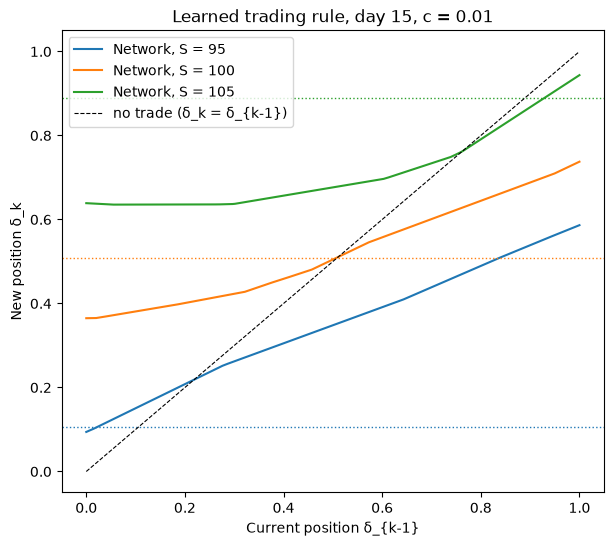

In [22]:
import matplotlib.pyplot as plt

k = 15                                  
delta_prev_grid = torch.linspace(0, 1, 200)

fig, ax = plt.subplots(figsize=(7, 6))
for S_val, color in zip([95, 100, 105], ["C0", "C1", "C2"]):
    x1v = torch.full_like(delta_prev_grid, np.log(S_val / K) / (sigma * np.sqrt(T)))
    x2v = torch.full_like(delta_prev_grid, tau[k] / T)
    with torch.no_grad():
        out = net_tc(torch.stack([x1v, x2v, delta_prev_grid], dim=-1)).squeeze(-1)
    ax.plot(delta_prev_grid, out, color=color, label=f"Network, S = {S_val}")
    ax.axhline(bs_delta(S_val, K, tau[k], sigma), color=color, ls=":", lw=1)

ax.plot([0, 1], [0, 1], "k--", lw=0.8, label="no trade (δ_k = δ_{k-1})")
ax.set_xlabel("Current position δ_{k-1}")
ax.set_ylabel("New position δ_k")
ax.set_title(f"Learned trading rule, day {k}, c = {c}")
ax.legend()
plt.savefig("../figures/no_trade_band.png", dpi=150, bbox_inches="tight")
plt.show()

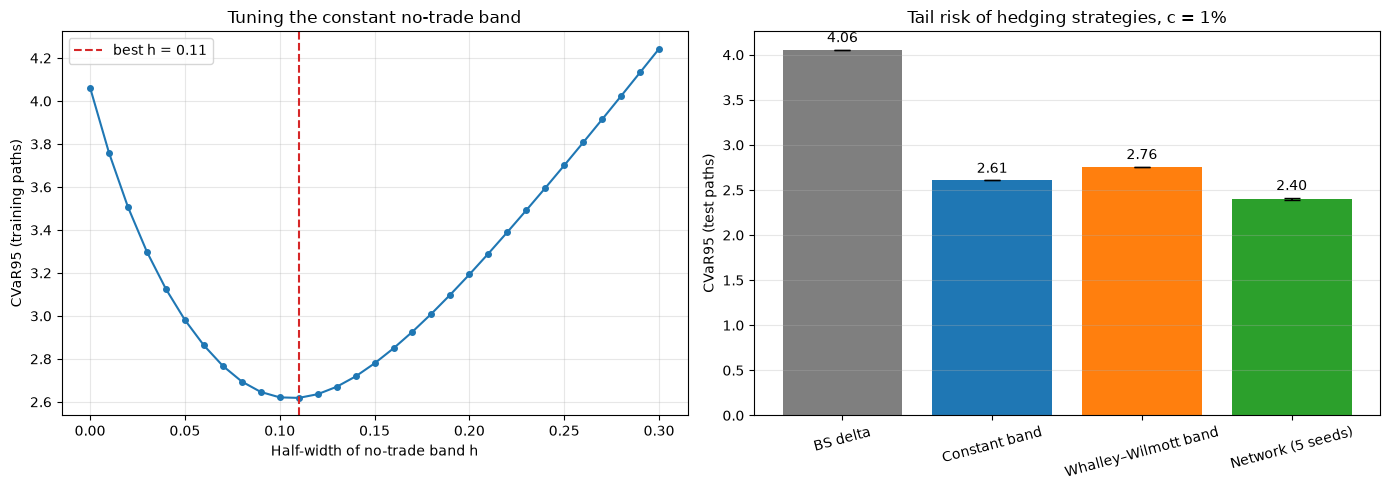

In [23]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))


ax1.plot(hs, cvars, "o-", ms=4)
ax1.axvline(h_best, color="C3", ls="--", label=f"best h = {h_best:.2f}")
ax1.set_xlabel("Half-width of no-trade band h")
ax1.set_ylabel("CVaR95 (training paths)")
ax1.set_title("Tuning the constant no-trade band")
ax1.legend()
ax1.grid(alpha=0.3)

names = ["BS delta", "Constant band", "Whalley–Wilmott band", "Network (5 seeds)"]
values = [
    cvar(compute_pnl(S_test, d_bs,   p0, K, c=c)),
    cvar(compute_pnl(S_test, d_band, p0, K, c=c)),
    cvar(compute_pnl(S_test, d_ww,   p0, K, c=c)),
    results[:, 0].mean(),
]
errors = [0, 0, 0, results[:, 0].std()]

bars = ax2.bar(names, values, yerr=errors, capsize=6, color=["C7", "C0", "C1", "C2"])
ax2.bar_label(bars, fmt="%.2f", padding=3)
ax2.set_ylabel("CVaR95 (test paths)")
ax2.set_title(f"Tail risk of hedging strategies, c = {c:.0%}")
ax2.tick_params(axis="x", rotation=15)
ax2.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.savefig("../figures/benchmark_comparison.png", dpi=150, bbox_inches="tight")
plt.show()